In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [3]:
class BatterState(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int
    
    sr: float
    bp: float
    bpb: float
    summary: str

In [ ]:
def calc_sr(state: BatterState):
    sr = (state['runs'] / state['balls'])*100
    return {'sr': sr}

def calc_bp(state: BatterState):
    bp = ((state['fours'] * 4 + state['sixes'] * 6) / state['runs']) * 100
    return {'bp': bp}

def calc_bpb(state: BatterState):
    bpb = state['balls'] / (state['fours'] + state['sixes'])
    return {'bpb': bpb}

def summary(state: BatterState):
    summary = f''' Strike Rate: {state['sr']}
        Boundary Percent: {state['bp']}
        Balls per boundary: {state['bpb']}
    '''
    return {'summary': summary}

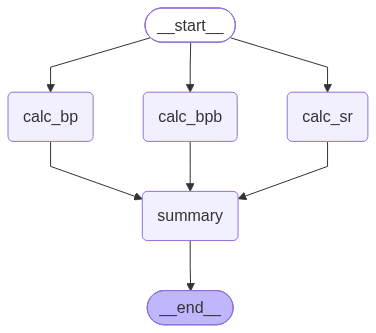

In [11]:
graph = StateGraph(BatterState)

graph.add_node('calc_sr', calc_sr)
graph.add_node('calc_bp', calc_bp)
graph.add_node('calc_bpb', calc_bpb)
graph.add_node('summary', summary)

graph.add_edge(START, 'calc_sr')
graph.add_edge(START, 'calc_bp')
graph.add_edge(START, 'calc_bpb')
graph.add_edge('calc_sr', 'summary')
graph.add_edge('calc_bp', 'summary')
graph.add_edge('calc_bpb', 'summary')
graph.add_edge('summary', END)

workflow = graph.compile()
workflow

In [12]:
initial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bp': 48.0,
 'bpb': 5.0,
 'summary': ' Strike Rate: 200.0 \n\n        Boundary Percent: 48.0 \n\n        Balls per boundary: 5.0\n    '}